# Data Analysis of the Rotterdam Dataset

In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.nonparametric.smoothers_lowess import lowess
import seaborn as sns
from scipy.stats import chi2
from lifelines.utils import concordance_index

from lifelines import CoxPHFitter, KaplanMeierFitter
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sksurv.util import Surv
from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored, integrated_brier_score
import torch
import torchtuples as tt
from pycox.models import CoxPH

## Loading Data and Simple Analysis

In [2]:
url = "https://raw.githubusercontent.com/vincentarelbundock/Rdatasets/master/csv/survival/gbsg.csv"


# download rotterdam from statsmodels. For the second dataset we have to download it directly as the get_rdataset was failing
rot_df = sm.datasets.get_rdataset("RotterdamBreastCancer_df", "OncoDataSets").data.reset_index(drop=True)

gbs_df = pd.read_csv(url, index_col=0).reset_index(drop=True)
gbs_df = gbs_df.sort_values("pid").reset_index(drop=True)

In [3]:
print(rot_df.shape)
rot_df.head()

(2982, 15)


,pid,year,age,meno,size,grade,nodes,pgr,er,hormon,chemo,rtime,recur,dtime,death
0,1,1992,74,1,<=20,3,0,35,291,0,0,1799,0,1799,0
1,2,1984,79,1,20-50,3,0,36,611,0,0,2828,0,2828,0
2,3,1983,44,0,<=20,2,0,138,0,0,0,6012,0,6012,0
3,4,1985,70,1,20-50,3,0,0,12,0,0,2624,0,2624,0
4,5,1983,75,1,<=20,3,0,260,409,0,0,4915,0,4915,0


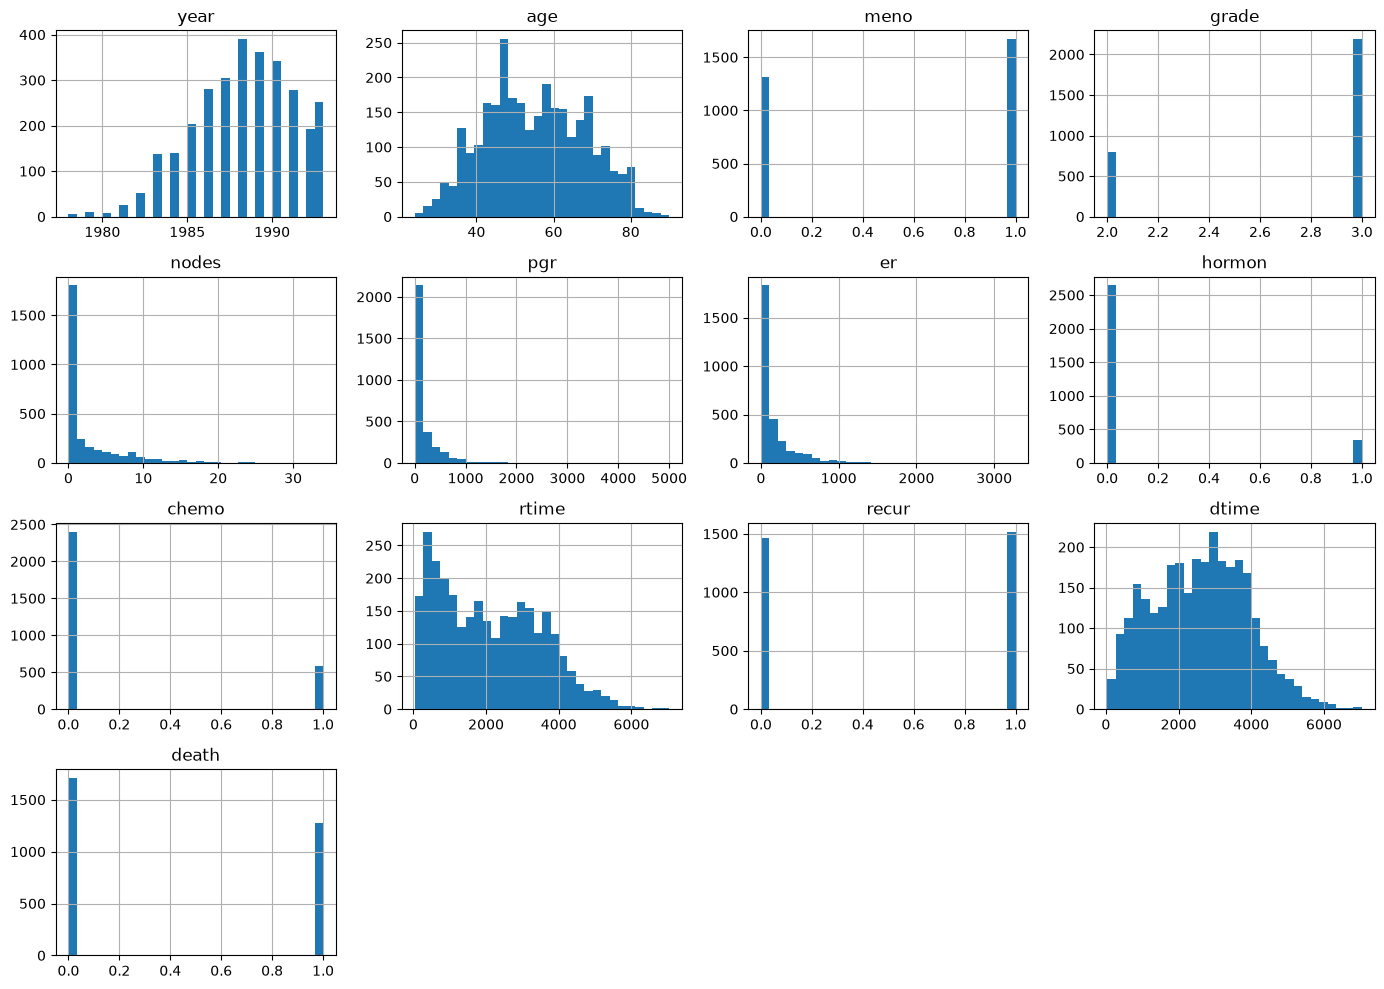

In [4]:
rot_df.drop(columns=["pid"]).hist(figsize=(14, 10), bins=30)
plt.tight_layout(); plt.show()

This shows us a few things. For grade we only have grade 2 and 3. We also see that there are a lot of surviving patients until about 2/3 of the way through the follow up. This motivates us choosing a strict cut off for our model prediction.

In [5]:
print(gbs_df.shape)
gbs_df.head()

(686, 11)


,pid,age,meno,size,grade,nodes,pgr,er,hormon,rfstime,status
0,1,38,0,18,3,5,141,105,0,1337,1
1,6,52,0,20,1,1,78,14,0,1420,1
2,13,47,0,30,2,1,422,89,0,1279,1
3,37,40,0,24,1,3,25,11,0,148,0
4,38,64,1,19,2,1,19,9,1,1863,0


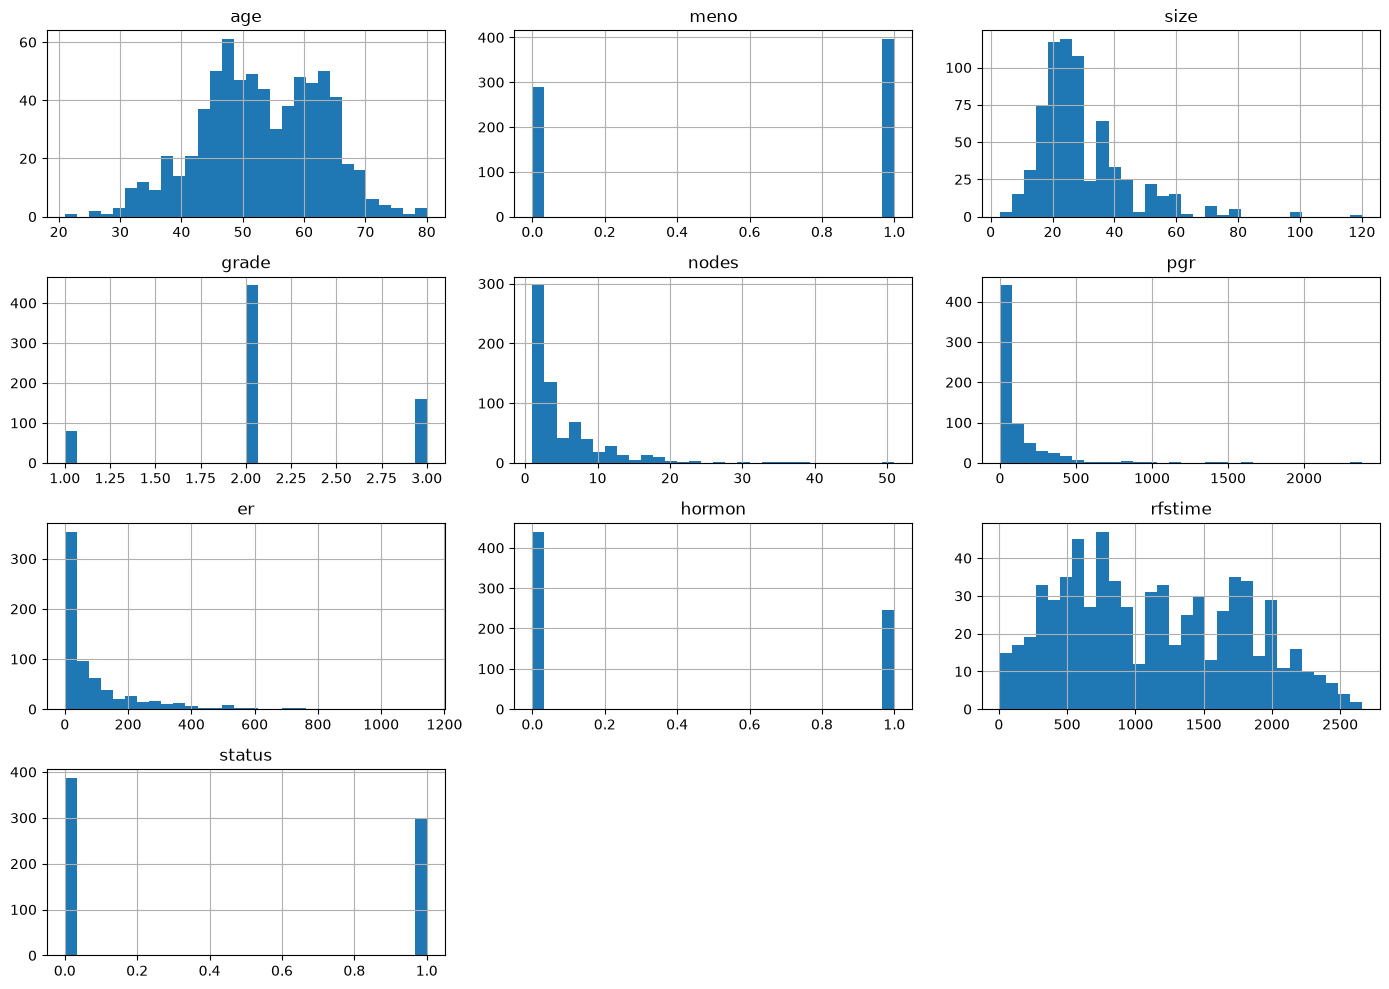

In [6]:
gbs_df.drop(columns=["pid"]).hist(figsize=(14, 10), bins=30)
plt.tight_layout(); plt.show()

We see that the two datasets are somewhat similar and include many of the same datapoints. Since we may use external validation we will make them as similar as possible as a starting point. The major differences are:

Size is coded in Rotterdam as <20, 20-50 and >50 while they have the exact tumor size for gbsg2. We will bin gbsg2 to have the same structure.

Chemo and year exist in the Rotterdam dataset but not in gbsg2 so we will drop these variables from rotterdam. Technically the all of the patients in the 2nd dataset received chemotherapy but in the Rotterdam dataset chemo was not randomized. It was given to patients that were thought to be higher risk mixing treatment benefit with the fact that patient's at higher risk received it. Also a cursory analysis (not listed here) showed that a basic Cox model did not improve with its inclusion. For these reasons we will exclude this column from our analysis.

The gbsg2 dataset only has node positive patients. This is an important point as our model will be based on the Rotterdam dataset as having no nodes is an important predictor of recurrence. Will make our validation a little less clean if we do attempt external validation.

gsbsg2 has its outcome as rfstime = days until recurrence or death (or censoring). Rotterdam has rtime = days until recurrence or until last checked recurrence and dtime = days until death or last seen alive. If we want to compare these two we will have to combine the outcomes in Rotterdam to measure rfstime.

The Rotterdam follows patients for a long time but we will choose a uniform cutoff for the prediction model. A good convention is 5 or 10 years. In our case we choose 10 as there are still a good number of patients alive at this point. We can see this if we just graph the number of patients who have not had an event over time.

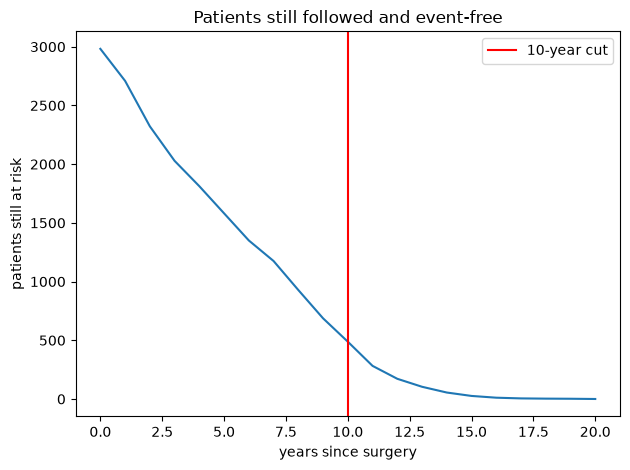

0     2982
5     1581
10     488
15      26
dtype: int64


In [7]:
# We convert the time to event into years
time = np.where(rot_df.recur == 1, rot_df.rtime, rot_df.dtime) / 365.25

years = np.arange(0, 21)
at_risk = []
for y in years:
    at_risk.append((time > y).sum())

plt.figure
plt.plot(years, at_risk)
plt.axvline(10, color="red", label="10-year cut")
plt.xlabel("years since surgery"); plt.ylabel("patients still at risk")
plt.title("Patients still followed and event-free")
plt.legend(); plt.tight_layout(); plt.show()

print(pd.Series(at_risk, index=years).loc[[0, 5, 10, 15]])

Here we see that there are still a good number of patients left at 10 years. As we get out to 15 years the patients left at risk drops precipitiously. Predictions made at this point would be based on fewer data points. 10 years is also good by convention as clinicians generally talk about 5 year and 10 year outcomes.

## Preparing the Rotterdam Dataset

In [8]:
# First we combine death and recurrence into one event as that is what our model will use as its outcome
rot_df["event"] = np.maximum(rot_df.recur, rot_df.death)

# We calculate time to that event by first checking if there was recurrence and using that time, if no recurrence we use the death time (or last known allive)
rot_df["time"]  = np.where(rot_df.recur == 1, rot_df.rtime, rot_df.dtime).astype(float)

# We censor anyone that made it all the way to the end of the follow up
max_time_horizon = 10 * 365.25
rot_df.loc[rot_df.time > max_time_horizon, "event"] = 0
rot_df["time"] = rot_df.time.clip(upper=max_time_horizon)

#we code our tumor size column into binary 0/1 labels, only have to make 2 new binary columns as 0 in both implies it is <20
rot_df["size_20_50"] = (rot_df["size"].astype(str) == "20-50").astype(int)
rot_df["size_gt50"]  = (rot_df["size"].astype(str) == ">50").astype(int)

#we only have grade 2 and 3 tumors so if it is 0 for grade 3 then it means it is grade 2
rot_df["grade3"] = (rot_df["grade"] == 3).astype(int)

In [9]:
# we define our continuous and categorical variables here so that we can do some analysis later
continuous_var = ["age", "nodes", "er", "pgr"]
categorical_var = ["meno", "size_20_50", "size_gt50", "grade3", "hormon"]

In [10]:
print("Patients:", len(rot_df), "| Events:", int(rot_df.event.sum()))

Patients: 2982 | Events: 1644


In [11]:
rot_df.head()

,pid,year,age,meno,size,grade,nodes,pgr,er,hormon,chemo,rtime,recur,dtime,death,event,time,size_20_50,size_gt50,grade3
0,1,1992,74,1,<=20,3,0,35,291,0,0,1799,0,1799,0,0,1799.0,0,0,1
1,2,1984,79,1,20-50,3,0,36,611,0,0,2828,0,2828,0,0,2828.0,1,0,1
2,3,1983,44,0,<=20,2,0,138,0,0,0,6012,0,6012,0,0,3652.5,0,0,0
3,4,1985,70,1,20-50,3,0,0,12,0,0,2624,0,2624,0,0,2624.0,1,0,1
4,5,1983,75,1,<=20,3,0,260,409,0,0,4915,0,4915,0,0,3652.5,0,0,1


## Distribution and Variable Correlation

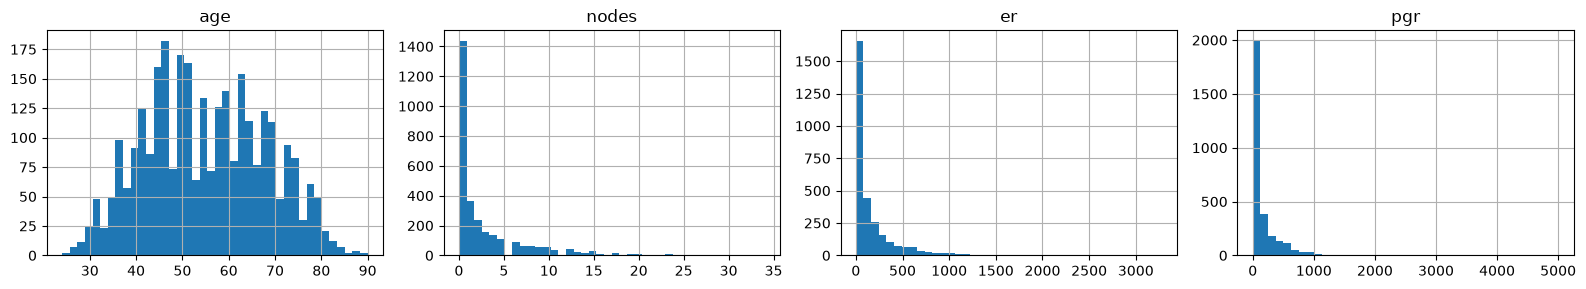

age      0.1
nodes    2.4
er       3.8
pgr      4.6
dtype: float64


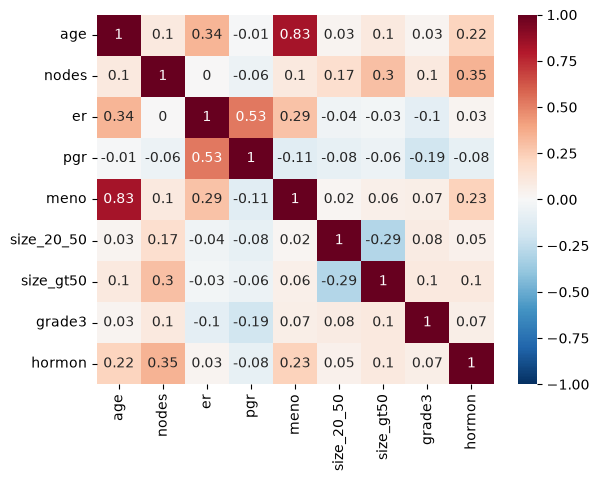

In [12]:
# lets look at our continuous variables again and see how skewed they are
rot_df[continuous_var].hist(bins=40, layout=(1, 4), figsize=(16, 3))
plt.tight_layout(); plt.show()
print(rot_df[continuous_var].skew().round(1))

# Correlation table, coloured like a heatmap
corr = rot_df[continuous_var + categorical_var].corr(method="spearman").round(2)
sns.heatmap(corr, annot=True, cmap="RdBu_r", vmin=-1, vmax=1); plt.show()

We see a few interesting things. Our age is distributed as expected with tails on each side indicating there are few very young patients and few very old patients. The other variables are highly skewed with pgr and er status having the highest skew. This can cause problems for two reasons: first skewed variables often have non linear effects that is to say the risk of going from 0 to 1 node is not the same as going from 1 to 2 nodes. Also extreme outliers can dominate the model or have an outsized effect. There are two ways to handle this. We could transform the data and check it against the outcome or we could use splines/fractional polynomials to account for these non-linear effect.

On the correlation map we see that there aren't too many variables that are direclty correlated except for menopause and age. These are highly correlated which makes sense as menopause occurs with increasing age. There is some correlation between pgr and er status of the tumor. Might not need both of these variables in our final model but we will let our selection criteria decide that later.

## Simple Linear Cox Model Variable Analysis

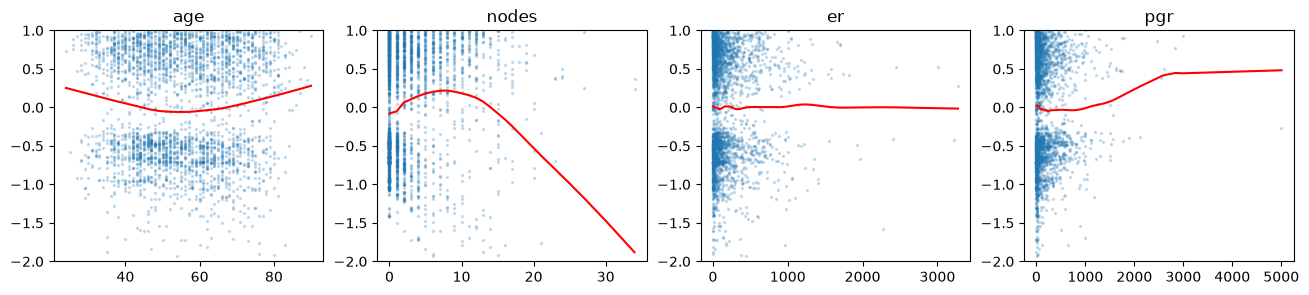

In [13]:
data = rot_df[continuous_var + categorical_var + ["time", "event"]]
cox_lin = CoxPHFitter().fit(data, "time", "event")
res = cox_lin.compute_residuals(data, kind="martingale")["martingale"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, var in zip(axes, continuous_var):
    x = rot_df.loc[res.index, var]
    trend = lowess(res, x, it=0)
    ax.scatter(x, res, s=2, alpha=0.2)
    ax.plot(trend[:, 0], trend[:, 1], "r")
    ax.set_ylim(-2, 1); ax.set_title(var)
plt.show()

Here we fit a simple linear cox model to our entire dataset for visualisation purposes. We then calculate the martingale residual for each patient which we then plot against the variable and we add a smoothed trend line. This residual reflects the difference between what actually happened and what the model expected to happen. 

If the value is positive it means that the model under-estimated the risk for that patient. If it is negative it means that the model over-estimated risk for that patient. What you want to see with these plots when you are analyzing variables with respect to their linearity is a trend line that is close to 0. A linear model that is handling each variable correctly will not be systematically wrong in one direction. However, if the variable has non linear effects then you will see that the trend line will be systematically biased in one direction of the other.

For age we have a u shaped trend line indicating that the linear model under-estimates risk at very young age and at very high age. We also see that for nodes and pgr (more dramatic for nodes then pgr) that the trend lines are non ideal as well, hinting at a certain non-linearity here. For nodes we see that initially it under-estimates risk but as we increase past 15 nodes it begins to over-estimates the risk, especially as we reach 30 nodes. For pgr, it initially predicts well but as we get to higher values it under-estimates the risk. Er however appears to well accounted for by the model as its trend line is flat around 0. While we will still train a baseline linear Cox model this will not be our best comparison for our deep learning approach. Instead we will look to handle these continuous variables with fractional polynomials to make a more robust Cox model.

## Fractional Polynomial Cox Model

In [14]:
# Here we have the different types of powers we will use, we will designate our 0 option as a log transformation later
POWERS = [-2, -1, -0.5, 0, 0.5, 1, 2, 3]

# We need positive numbers as this will cause our calculations to throw errors so we shift our variables by adding 1 to nodes, er, and pgr. Age needs no shift
# We scale our variables just for numerical tidiness though it is not strictly necessary (though very large number can make coefficients unreadable)
def shift_and_scale(df):
    fp_data = df.copy()
    fp_data["age"]   = fp_data["age"] / 10
    fp_data["nodes"] = fp_data["nodes"] + 1
    fp_data["er"]    = (fp_data["er"] + 1) / 100
    fp_data["pgr"]   = (fp_data["pgr"] + 1) / 100
    return fp_data

def fractional_polynomial_terms(x, powers):
    #this line fixes a bug I was having where integers could not be raised to a negative exponent
    x = x.astype(float)
    terms, prev = [], None
    for p in powers:
        #if 0 we do log(x)
        if p == 0:
            t = np.log(x)
        else:
            t = x ** p
        #this is a convention of fractional polynomials, if you give it a second term that is identical you multiple it by log(x)
        #so if the terms are (1,1) then the terms will be b₁ * x + b₂ * x * log(x)
        if p == prev:
            t = t * np.log(x)
        terms.append(t); prev = p
    return terms


def log_likelihood(data, var, powers):
    # builds our data, removing our variable of interest as we will be transforming this variable
    X = data[continuous_var + categorical_var + ["time", "event"]].drop(columns=var)

    # transforms our variable of interest based on the powers chosen
    terms = fractional_polynomial_terms(data[var], powers)

    # for the first term we make a variable_1 column (occurs for both FP1 and FP2)
    X[var + "_1"] = terms[0]

    # adds a second term if we are looking at FP2
    if len(terms) == 2:
        X[var + "_2"] = terms[1]

    #returns the log_likelihood so we can make comparisons        
    return CoxPHFitter().fit(X, "time", "event").log_likelihood_

#alpha is 0.05 so we only choose one term over another if it satisfies this statistical requirement on the chi2 test
def select_form(data, var, alpha=0.05):

    # here we make all our possible combinations of powers for both 1 term and 2 term fractional polynomial possibilities
    one_power  = [(p,) for p in POWERS]
    two_powers = list(itertools.combinations_with_replacement(POWERS, 2))

    # fit each candidate and get its log likelihood which is a way to see how well your model explains the data. We store this in a dictionary with the key = power
    likelihoods = {}
    for powers in one_power + two_powers:
        likelihoods[powers] = log_likelihood(data, var, powers)

    best_one = max(one_power, key=likelihoods.get)
    best_two = max(two_powers, key=likelihoods.get)

    # now we evaluate if our likelihoods obtained are actually better using the likelihood ratio test statistic which is 2 * difference in LL with alpha as our cutoff
    # for our first comparison we compare our best two term model with the linear model. DF is 3 because there are (4-1)
    if chi2.sf(2 * (likelihoods[best_two] - likelihoods[(1,)]), 3) >= alpha:      # two powers not better than a straight line
        return (1,)
        
    # our second comparison compares the best two term model with the best one term model for that variable. DF is 1 less (4-2)
    if chi2.sf(2 * (likelihoods[best_two] - likelihoods[best_one]), 2) >= alpha:
        return best_one
        
    return best_two


def select_forms(data):
    forms = {} 
    for var in continuous_var:
        forms[var] = select_form(data, var)
    return forms

In [15]:
FORMS = select_forms(shift_and_scale(rot_df))
FORMS

{'age': (2, 3), 'nodes': (1, 1), 'er': (1,), 'pgr': (1,)}

So for age it is two terms age^2 and age^3 which likely allows it to account for the u shaped data. For nodes it is two terms nodes and nodes*log(nodes). Finally for er and pgr our select best automatic rule did not find that it improved the model enough to add polynomial terms to these variables so they stay linear. Lets look at the same residuals we looked at before now.

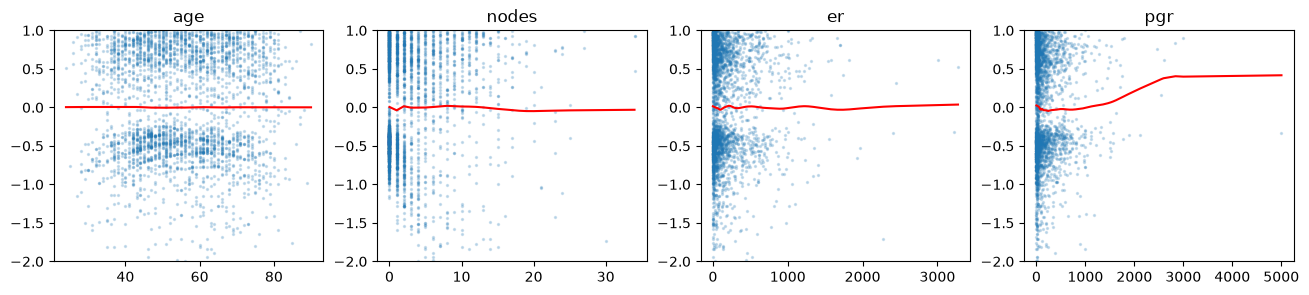

In [16]:
#we write a small function to build our fractional polynomial terms for each variable, basically a modification of what we did above

def build_fp_table(df, forms):
    
    #first scale and shift the data
    data = shift_and_scale(df)
    
    #start with just our categorical variables in our dataset
    X = data[categorical_var + ["time", "event"]].copy()
    
    for var in continuous_var:
        terms = fractional_polynomial_terms(data[var], forms[var])
        X[var + "_1"] = terms[0]        
        if len(terms) == 2:
            X[var + "_2"] = terms[1]

    return X

# now we check the same residuals we checked before

X_fp = build_fp_table(rot_df, FORMS)
cox_fp = CoxPHFitter().fit(X_fp, "time", "event")
res_fp = cox_fp.compute_residuals(X_fp, kind="martingale")["martingale"]

fig, axes = plt.subplots(1, 4, figsize=(16, 3))
for ax, var in zip(axes, continuous_var):
    x = rot_df.loc[res_fp.index, var]
    trend = lowess(res_fp, x, it=0)
    ax.scatter(x, res_fp, s=2, alpha=0.2)
    ax.plot(trend[:, 0], trend[:, 1], "r")
    ax.set_ylim(-2, 1); ax.set_title(var)
plt.show()

In [17]:
# We can confirm the visual improvement we are seeing by comparing the AIC of each model (AIC = 2 × (number of parameters) − 2 × (log-likelihood))
# This value balances the number of parameters with how well the model fits. A lower number is better. If the difference is less than 2 probably not important.
# generally a difference of greater than 10 is strong evidence that the model with the lower AIC score is the better one

print("AIC of linear model:", round(cox_lin.AIC_partial_, 1))
print("AIC of FP model:    ", round(cox_fp.AIC_partial_, 1))
print("Improvement:        ", round(cox_lin.AIC_partial_ - cox_fp.AIC_partial_, 1))

AIC of linear model: 24419.3
AIC of FP model:     24267.9
Improvement:         151.5


## Feature Selection

After consideration we decided to retain all candidate variables even though there is some correlation between variables. This was done for multiple reasons:

1. We have only 9 model columns (4 continuous = age, nodes, er, pgr; 5 categorical = meno, size_20_50, size_gt50, grade3, hormon) and have 1713 events in total of which 1644 events fall within our 10 year time frame. This means there are on average 183 events per variable and if we take our more complex FP model about 149 events per column in the FP model dataset. This is well above the rough rule of 10-20 events per variable.
2. We would like to compare models using similar datasets. Our deep learning and random forest approaches will receive all the candidate variables and if we used lasso regression we would be comparing models that are using different variables.
3. All of the variables are established prognostic clinical factors in breast cancer.

As seen in the Spearman correlation above some variables do correlate notably er and pgr as well as age and menopause. Correlation between variables can make individual coefficients for the Cox model harder to interpret but it doesn't generally have an effect on the prediction performance which is what we are comparing here.

In [18]:
#for fun lets look at how the coefficients of each parameter change on our fractional polynomial model with different lasso penalties
results = {}
for penalty in [0.001, 0.01, 0.05, 0.1]:
    m = CoxPHFitter(penalizer=penalty, l1_ratio=1.0).fit(X_fp, "time", "event")
    results[penalty] = m.params_

pd.DataFrame(results).round(3)

,0.001,0.010,0.050,0.100
covariate,,,,
meno,0.201,0.000,0.000,0.000
size_20_50,0.282,0.306,0.132,0.000
size_gt50,0.458,0.539,0.319,0.000
grade3,0.321,0.292,0.158,0.000
hormon,-0.300,-0.087,0.000,0.000
age_1,-0.071,0.000,0.000,0.000
age_2,0.008,0.000,0.000,0.000
nodes_1,0.415,0.154,0.070,0.065
nodes_2,-0.108,-0.025,0.000,0.000


This shows us that nodes is by far the strongest predictor, retaining its coefficient even with a very strong penalty. Tumor size and grade are the next two move important with large coefficients that only disappear with the highest penalty. Hormone therapy and pgr are weaker with hormone status and er dropping even faster. Age also drops quickly but this is probably related to the fact that we transformed this into age^2 and age^3 and these two terms are extremely highly correlated with each other. The real question is would using these penalties even change the performance? This is easily investigated by just looking at the C-index for each penalized version of the model.

In [19]:
from lifelines.utils import k_fold_cross_validation

cv_results = {}
for penalty in [0, 0.001, 0.005, 0.01, 0.05]:
    scores = k_fold_cross_validation(CoxPHFitter(penalizer=penalty, l1_ratio=1.0), X_fp, "time", "event", k=5, scoring_method="concordance_index", seed=0)
    cv_results[penalty] = np.mean(scores)

pd.Series(cv_results, name="CV C-index").rename_axis("penalty").round(4).to_frame()

,CV C-index
penalty,
0.000,0.6795
0.001,0.6793
0.005,0.6727
0.010,0.6698
0.050,0.6701


Our simple analysis shows that our best model is the unpenalized model with the highest c-index. Each other version has a lower C-index than the unpenalized model. This confirms our decision to keep all variables for our final dataset

## Defining our Models

We will build 5 total models:

1. Kaplan–Meier = used as a baseline comparison for Brier score
2. Cox linear = our most basic model which does not account for non-linear relationships
3. Cox FP = our fractional polynomial cox model to help account for non-linearity
4. Random survival forest = machine learning model that captures non linear effects and interactions automatically
5. DeepSurv = neural network version of the Cox model

Cross fold validation will be used to evaluate our models (k = 5) and tuning of model parameters will be done on the training data only and not the validation portion of each fold.

In [20]:
SEED = 42

#we hard code the time interval here for time predictions here from 1 to 9 years
#the brier score will fail if we calculate up to the 10 year mark (need to be just below it)
TIMES = np.arange(1, 10) * 365.25

#we define our dataset which is the continuous and categorical variables described above
predictors = continuous_var + categorical_var

#possible powers that can be selected, same as above
POWERS = [-2, -1, -0.5, 0, 0.5, 1, 2, 3] 


def kaplan_meier_model(train, test):
    km = KaplanMeierFitter().fit(train["time"], train["event"])
    risk = np.zeros(len(test))
    curve = km.survival_function_at_times(TIMES).values
    surv = np.tile(curve, (len(test), 1))
    return risk, surv

def cox_linear_model(train, test):
    cox = CoxPHFitter().fit(train[predictors + ["time", "event"]], duration_col="time", event_col="event")
    risk = cox.predict_partial_hazard(test[predictors]).values
    surv = cox.predict_survival_function(test[predictors], times=TIMES).T.values
    return risk, surv

def cox_fp_model(train, test):

    #selects the best forms using our code from above, very important that it selects best forms based on the training data here, otherwise leakage!
    forms = select_forms(shift_and_scale(train))
    fp_choices.append(forms)

    #now we build our fp terms for our X_train and X_test
    X_train = build_fp_table(train, forms)
    X_test = build_fp_table(test, forms).drop(columns=["time", "event"])

    #fit our model on X_train
    cox = CoxPHFitter().fit(X_train, "time", "event")

    #produce our risk and survival
    risk = cox.predict_partial_hazard(X_test).values
    surv = cox.predict_survival_function(X_test, times=TIMES).T.values
    return risk, surv

def random_forest_model(train, test):
    y_train = Surv.from_arrays(event=train["event"].astype(bool), time=train["time"])

    #now we tune our random_forest, the most important of which is the number of leafs but we will also tune for the max_features
    best_random_forest = None

    #we allow the random forests to choose from 5, 15 or 30 patients left in each of its terminal nodes
    for leaf in [5, 15, 30]:
        #we also artificially constrain each split decision to a certain number of random features from very restrictive (2) to more permissive (5)
        # if every forest tree had all choices available they would tend to split on nodes first ... by limiting the algorithm we get more diverse trees
        for features in [2, 3, 5]:
            #here we train many different versions of the random forest with our different combinations
            #for each run a small portion of the training set is held out and an out of bag score is calculated on that
            random_forest = RandomSurvivalForest(n_estimators=300, min_samples_leaf=leaf, max_features=features,
                                       oob_score=True, n_jobs=-1, random_state=SEED)
            random_forest.fit(train[predictors], y_train)
            if best_random_forest is None or random_forest.oob_score_ > best_random_forest.oob_score_:
                best_random_forest = random_forest

    #we record the best chosen parameters for reporting later
    forest_choices.append({"min_samples_leaf": best_random_forest.min_samples_leaf,
                           "max_features": best_random_forest.max_features,})

    risk = best_random_forest.predict(test[predictors])

    #here the code is slightly different than above, lifelines builds the table we will need for the brier score automatically (after transposing it)
    #scikit returns a curve object for each patient with survival probabilities, so we build the table of probabilities at each time point we will need
    surv = []
    for curve in best_random_forest.predict_survival_function(test[predictors]):
        surv.append(curve(TIMES))
    surv = np.array(surv)
        
    return risk, surv


def deepsurv_model(train, test):
    torch.manual_seed(SEED)

    #we scale our inputs as neural networks work best when everything is scaled in the same range
    #we scale based on the training set and not the overall data set to avoid leakage
    scaler = StandardScaler().fit(train[predictors])

    #here we will need to validate our hyperparameter choice and to decide when to do early stopping so we create a small validation set within each training fold
    train_part, validation = train_test_split(train, test_size=0.2, random_state=SEED)

    #we call our scaler which was initiated above and scale our predictors
    x_train = scaler.transform(train_part[predictors]).astype("float32")
    x_validation = scaler.transform(validation[predictors]).astype("float32")
    x_test = scaler.transform(test[predictors]).astype("float32")

    #we define our time and event outcomes
    y_train = (train_part["time"].values.astype("float32"), train_part["event"].values.astype("float32"))
    y_validation = (validation["time"].values.astype("float32"), validation["event"].values.astype("float32"))

    # now we define the hyperparameters we will tune
    #network size options = one hidden layer of 16, two hidden layers of 32, or two hidden layers of 64 neurons
    layer_options = [[16], [32, 32], [64, 64]]

    #we give two drop out options, none or 0.2
    dropout_options = [0.0, 0.2]

    #we try 3 learning rates (1e-3 is standard)
    learning_rate_options = [1e-4, 1e-3, 1e-2]

    # now we train every combination and keep the best model (18 total combinations), setting best loss to infinity at the beginning
    best_model, best_loss = None, np.inf
    
    for layers in layer_options:
        for dropout in dropout_options:
            for learning_rate in learning_rate_options:
                #we define our network which is a simple multi-layer perceptron with layers and drop out defined based on the options
                #output_bias is false because cox does not include an intercept
                network = tt.practical.MLPVanilla(len(predictors), layers, 1, dropout=dropout, output_bias=False)

                #now we wrap our network in a Cox proportional hazard model. The network replaces the linear formula of the standard Cox model
                #this allows us to use a neural network instead and still provide survival predictions
                model = CoxPH(network, tt.optim.Adam(lr=learning_rate))

                #we fit our model and log its results
                log = model.fit(x_train, y_train, batch_size=128, epochs=300, verbose=False,
                                callbacks=[tt.callbacks.EarlyStopping(patience=15)],
                                val_data=(x_validation, y_validation))                
                validation_loss = log.to_pandas()["val_loss"].min()
                if validation_loss < best_loss:
                    best_model, best_loss = model, validation_loss
                    best_settings = {"layers": layers, "dropout": dropout, "learning_rate": learning_rate}
    deepsurv_choices.append(best_settings)

    # after tuning our model hyperparameters and finding the best model we evaluate it on our test set
    best_model.compute_baseline_hazards()
    risk = best_model.predict(x_test).ravel()

    # build our risk table at each time point like we did for the random forest
    curves = best_model.predict_surv_df(x_test)                 
    surv = []
    for patient in curves.columns:
        curve = curves[patient]
        surv.append(curve.reindex(TIMES, method="ffill").values)   
    surv = np.array(surv)                                           
    return risk, surv

In [21]:
#we define all our models that we will be using here
models = {
    "Kaplan-Meier": kaplan_meier_model,
    "Cox linear":   cox_linear_model,
    "Cox FP":       cox_fp_model,
    "RSF":          random_forest_model,
    "DeepSurv":     deepsurv_model}

#we make some empty lists here to store the choices of our models
fp_choices = []
forest_choices = []
deepsurv_choices = []

#we create an empty dictionary with 2982 empty slots per model, one for each patient so that later we can do bootstrapping on the out of fold data for each training
out_of_fold = {}
for name in models:
    out_of_fold[name] = np.full(len(rot_df), np.nan)

#we run all the models we defined above now in order using k-fold cross validation
folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []

for fold, (train_idx, val_idx) in enumerate(folds.split(rot_df)):
    train_df = rot_df.iloc[train_idx]
    val_df = rot_df.iloc[val_idx]

    y_train = Surv.from_arrays(event=train_df["event"].astype(bool), time=train_df["time"])
    y_val = Surv.from_arrays(event=val_df["event"].astype(bool), time=val_df["time"])

    for name, fit_predict in models.items():
        risk, surv = fit_predict(train_df, val_df)

        #we fill in our empty dictionary before with the out of fold predictions, each time we train on a fold it fills in 20% of the table
        out_of_fold[name][test_idx] = 1 - surv[:, -1]
        
        c_index = concordance_index_censored(test["event"].values.astype(bool),
                                             test["time"].values, risk)[0]
        
        ibs = integrated_brier_score(y_train, y_test, surv, TIMES)
        rows.append({"fold": fold, "model": name, "C-index": c_index, "IBS": ibs})
        print("\n--- Fold", fold, "---")
        print(name, "| C-index:", round(c_index, 3), "| IBS:", round(ibs, 3))

results = pd.DataFrame(rows)
choices_fp = pd.DataFrame(fp_choices)
choices_forest = pd.DataFrame(forest_choices)
choices_deepsurv = pd.DataFrame(deepsurv_choices)


--- Fold 0 ---
Kaplan-Meier | C-index: 0.5 | IBS: 0.223

--- Fold 0 ---
Cox linear | C-index: 0.678 | IBS: 0.19

--- Fold 0 ---
Cox FP | C-index: 0.694 | IBS: 0.182

--- Fold 0 ---
RSF | C-index: 0.692 | IBS: 0.184

--- Fold 0 ---
DeepSurv | C-index: 0.677 | IBS: 0.188

--- Fold 1 ---
Kaplan-Meier | C-index: 0.5 | IBS: 0.221

--- Fold 1 ---
Cox linear | C-index: 0.645 | IBS: 0.199

--- Fold 1 ---
Cox FP | C-index: 0.669 | IBS: 0.194

--- Fold 1 ---
RSF | C-index: 0.67 | IBS: 0.192

--- Fold 1 ---
DeepSurv | C-index: 0.662 | IBS: 0.195

--- Fold 2 ---
Kaplan-Meier | C-index: 0.5 | IBS: 0.22

--- Fold 2 ---
Cox linear | C-index: 0.666 | IBS: 0.193

--- Fold 2 ---
Cox FP | C-index: 0.672 | IBS: 0.189

--- Fold 2 ---
RSF | C-index: 0.677 | IBS: 0.187

--- Fold 2 ---
DeepSurv | C-index: 0.668 | IBS: 0.192

--- Fold 3 ---
Kaplan-Meier | C-index: 0.5 | IBS: 0.226

--- Fold 3 ---
Cox linear | C-index: 0.666 | IBS: 0.197

--- Fold 3 ---
Cox FP | C-index: 0.678 | IBS: 0.191

--- Fold 3 ---
RSF 

In [22]:
results

,fold,model,C-index,IBS
0,0,Kaplan-Meier,0.500000,0.223145
1,0,Cox linear,0.678081,0.190130
2,0,Cox FP,0.693590,0.182022
3,0,RSF,0.692453,0.183674
4,0,DeepSurv,0.677128,0.187806
5,1,Kaplan-Meier,0.500000,0.221245
6,1,Cox linear,0.645027,0.199367
7,1,Cox FP,0.669252,0.194200
8,1,RSF,0.669689,0.191961
9,1,DeepSurv,0.661991,0.195003


In [23]:
print("Final FP forms:"); display(pd.DataFrame(fp_choices))
print("Final forest settings:"); display(pd.DataFrame(forest_choices))
print("Final DeepSurv settings:"); display(pd.DataFrame(deepsurv_choices))

Final FP forms:


,age,nodes,er,pgr
0,"(2, 2)","(1, 1)","(1,)","(1,)"
1,"(2, 3)","(1, 1)","(1,)","(0.5, 2)"
2,"(2, 2)","(0.5, 1)","(1,)","(1,)"
3,"(3, 3)","(1, 1)","(1,)","(1,)"
4,"(2, 3)","(-2, -1)","(1,)","(1,)"


Final forest settings:


,min_samples_leaf,max_features
0,30,3
1,15,3
2,15,2
3,30,2
4,30,2


Final DeepSurv settings:


,layers,dropout,learning_rate
0,"[32, 32]",0.0,0.0001
1,"[32, 32]",0.2,0.0100
2,"[64, 64]",0.2,0.0100
3,"[64, 64]",0.0,0.0100
4,[16],0.2,0.0100


## Bootstrapping Confidence Intervals for C-index

In [24]:
rng = np.random.default_rng(SEED)
events = rot_df["event"].values.astype(bool)
times = rot_df["time"].values
compare = ["Cox linear", "Cox FP", "RSF", "DeepSurv"]

# we resample patients from the out of fold predictions 10000 times and calculate the C-index
boot_rows = []
for b in range(1000):
    idx = rng.choice(len(rot_df), size=len(rot_df), replace=True)
    row = {}
    for name in compare:
        row[name] = concordance_index(times[idx], -out_of_fold[name][idx], events[idx])
    boot_rows.append(row)
boot = pd.DataFrame(boot_rows)

In [25]:
pooled = {}
for name in compare:
    pooled[name] = concordance_index(times, -out_of_fold[name], events)

ibs = results.groupby("model")["IBS"].agg(["mean", "std"])

table1 = pd.DataFrame({
    "C-index": pd.Series(pooled),
    "95% CI low": boot.quantile(0.025),
    "95% CI high": boot.quantile(0.975),
    "IBS mean": ibs["mean"],
    "IBS SD": ibs["std"],}).round(3).loc[list(models)]
table1

,C-index,95% CI low,95% CI high,IBS mean,IBS SD
Kaplan-Meier,NaN,NaN,NaN,0.222,0.002
Cox linear,0.663,0.650,0.677,0.195,0.004
Cox FP,0.678,0.665,0.691,0.189,0.005
RSF,0.674,0.662,0.688,0.189,0.004
DeepSurv,0.673,0.659,0.686,0.191,0.003


In [26]:
diffs = boot.drop(columns="Cox FP").sub(boot["Cox FP"], axis=0)

table2 = pd.DataFrame({
    "difference": diffs.mean(),
    "95% CI low": diffs.quantile(0.025),
    "95% CI high": diffs.quantile(0.975),
}).round(3)
table2

,difference,95% CI low,95% CI high
Cox linear,-0.015,-0.021,-0.009
RSF,-0.004,-0.009,0.002
DeepSurv,-0.005,-0.012,0.000


In [27]:
results.groupby("model")["IBS"].agg(["mean", "std"]).round(3)

,mean,std
model,,
Cox FP,0.189,0.005
Cox linear,0.195,0.004
DeepSurv,0.191,0.003
Kaplan-Meier,0.222,0.002
RSF,0.189,0.004


## External Validation

In [28]:
# First we have to build our gbs dataset similarly to our rottedam dataset
gbs_df["time"] = gbs_df["rfstime"].astype(float)
gbs_df["event"] = gbs_df["status"]

# we bin our sizes to the same categorical sizing, we also code our grade the same way
gbs_df["size_20_50"] = ((gbs_df["size"] > 20) & (gbs_df["size"] <= 50)).astype(int)
gbs_df["size_gt50"]  = (gbs_df["size"] > 50).astype(int)
gbs_df["grade3"]     = (gbs_df["grade"] == 3).astype(int)

print("Patients:", len(gbs_df), "| Events:", int(gbs_df["event"].sum()),
      "| Longest follow-up (years):", round(gbs_df["time"].max() / 365.25, 1))

Patients: 686 | Events: 299 | Longest follow-up (years): 7.3


In [29]:
TIMES = np.arange(1, 7) * 365.25

# reset the choice lists so they record only the final models' choices
fp_choices = []
forest_choices = []
deepsurv_choices = []

y_gbs = Surv.from_arrays(event=gbs_df["event"].astype(bool), time=gbs_df["time"])

external_rows = []
external_pred = {}

for name, model_function in models.items():
    #we call the same model functions we already build but here we pass rotterdam in its entirety as the training set and gbs as the test set
    risk, surv = model_function(rot_df, gbs_df)
    external_pred[name] = 1 - surv[:, -1]

    c_index = concordance_index_censored(gbs_df["event"].values.astype(bool),
                                         gbs_df["time"].values, risk)[0]
    ibs = integrated_brier_score(y_gbs, y_gbs, surv, TIMES)
    external_rows.append({"model": name, "C-index": round(c_index, 3), "IBS": round(ibs, 3)})
    print(name, "| C-index:", round(c_index, 3), "| IBS:", round(ibs, 3))

external = pd.DataFrame(external_rows)
external

Kaplan-Meier | C-index: 0.5 | IBS: 0.219
Cox linear | C-index: 0.655 | IBS: 0.193
Cox FP | C-index: 0.676 | IBS: 0.187
RSF | C-index: 0.676 | IBS: 0.188
DeepSurv | C-index: 0.682 | IBS: 0.184


,model,C-index,IBS
0,Kaplan-Meier,0.500,0.219
1,Cox linear,0.655,0.193
2,Cox FP,0.676,0.187
3,RSF,0.676,0.188
4,DeepSurv,0.682,0.184


In [30]:
print("Final FP forms:"); display(pd.DataFrame(fp_choices))
print("Final forest settings:"); display(pd.DataFrame(forest_choices))
print("Final DeepSurv settings:"); display(pd.DataFrame(deepsurv_choices))

Final FP forms:


,age,nodes,er,pgr
0,"(2, 3)","(1, 1)","(1,)","(1,)"


Final forest settings:


,min_samples_leaf,max_features
0,30,2


Final DeepSurv settings:


,layers,dropout,learning_rate
0,"[64, 64]",0.2,0.01


## Bootstrapping Confidence Intervals of External Validation

In [31]:
gbs_events = gbs_df["event"].values.astype(bool)
gbs_times = gbs_df["time"].values

boot_rows = []
for b in range(1000):
    idx = rng.choice(len(gbs_df), size=len(gbs_df), replace=True)
    row = {}
    for name in compare:
        row[name] = concordance_index_censored(gbs_events[idx], gbs_times[idx], external_pred[name][idx])[0]
    boot_rows.append(row)
boot_gbs = pd.DataFrame(boot_rows)

In [32]:
table3 = external.set_index("model")

# recompute the C-index from the same predictions the bootstrap used
for name in compare:
    table3.loc[name, "C-index"] = round(concordance_index_censored(gbs_events, gbs_times, external_pred[name])[0], 3)

table3["C-index 95% CI low"] = boot_gbs.quantile(0.025).round(3)
table3["C-index 95% CI high"] = boot_gbs.quantile(0.975).round(3)
table3

,C-index,IBS,C-index 95% CI low,C-index 95% CI high
model,,,,
Kaplan-Meier,0.500,0.219,NaN,NaN
Cox linear,0.655,0.193,0.622,0.688
Cox FP,0.676,0.187,0.644,0.708
RSF,0.674,0.188,0.640,0.705
DeepSurv,0.682,0.184,0.650,0.711


In [33]:
#Different table
diffs_gbs = boot_gbs.drop(columns="Cox FP").sub(boot_gbs["Cox FP"], axis=0)

table4 = pd.DataFrame({
    "difference": diffs_gbs.mean(),
    "95% CI low": diffs_gbs.quantile(0.025),
    "95% CI high": diffs_gbs.quantile(0.975),
}).round(3)
display(table4)

,difference,95% CI low,95% CI high
Cox linear,-0.021,-0.039,-0.003
RSF,-0.002,-0.017,0.013
DeepSurv,0.005,-0.007,0.019


## Importance Evaluation for our Best Model (FP Cox)

In [35]:
#we know our best forms for our polynomial terms from the experiment in the exploratory data analysis
forms = {'age': (2, 3), 'nodes': (1, 1), 'er': (1,), 'pgr': (1,)}

#we build our full data set using those forms and we train a full model on the entire Rotterdam dataset for determining importance
X_full = build_fp_table(rot_df, forms)
importance_model = CoxPHFitter().fit(X_full, "time", "event")

variable_columns = {}

#categorical columns dont change so we just add them manually
variable_columns["tumour size"] = ["size_20_50", "size_gt50"]
variable_columns["grade 3"] = ["grade3"]
variable_columns["menopause"] = ["meno"]
variable_columns["hormone therapy"] = ["hormon"]

#since FP adds multiple terms to our dataframe for each variable we need to be sure to remove all terms related to that variable
#we do this with a small loop which ensures that both columns are removed if there are two terms
for var in continuous_var:
    columns = []
    for column in X_full.columns:
        if column.startswith(var + "_"):
            columns.append(column)
    variable_columns[var] = columns

In [36]:
rows = []
for variable, columns in variable_columns.items():
    masked_model = CoxPHFitter().fit(X_full.drop(columns=columns), "time", "event")

    #we do the same likelihood ratio test we did in the exploratory data analysis
    chi_square = 2 * (importance_model.log_likelihood_ - masked_model.log_likelihood_)
    df = len(columns)
    rows.append({"variable": variable,
                 "chi-square": round(chi_square, 1),
                 "p-value": chi2.sf(chi_square, df)})

importance = pd.DataFrame(rows).sort_values("chi-square", ascending=False)
importance

,variable,chi-square,p-value
5,nodes,332.4,6.609375e-73
4,age,35.3,2.133203e-08
0,tumour size,35.0,2.563732e-08
1,grade 3,28.9,7.427665e-08
3,hormone therapy,16.5,4.830971e-05
2,menopause,9.3,2.229950e-03
7,pgr,0.6,4.487370e-01
6,er,0.4,5.102572e-01


## Sources

https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Cox%20residuals.html

https://towardsdatascience.com/multivariate-fractional-polynomials-why-isnt-this-used-more-1a1fa9ead12c/

https://www.statisticshowto.com/likelihood-ratio-tests/

https://arxiv.org/abs/1606.00931 (DeepSurv: Personalized Treatment Recommender System Using A Cox Proportional Hazards Deep Neural Network)

https://pmc.ncbi.nlm.nih.gov/articles/PMC3667097/ (External validation of a Cox prognostic model: principles and methods)

Claude was used for debugging code as well as for plotting syntax